# RT-DETR R50-vd - Model Training and Experiments

This notebook presents the results of the RT-DETR experiments.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)

In [2]:
TASK_DIR = Path('.').resolve()
ROOT = TASK_DIR.parent
DATA_DIR = ROOT.parent / 'datasets/multiple-object-video-detection-hw-2-ucu-ai-2026'
METRICS = ['mAP', 'AP50', 'AP75', 'APs', 'APm', 'APl', 'AR']
BASELINE = 'recipe_warmup_ema'

## Scene density and the number of queries

In [5]:
train_coco = json.loads((DATA_DIR / 'train/annotations_coco.json').read_text())
objects_per_frame = pd.Series(0, index=[int(image['id']) for image in train_coco['images']])
for annotation in train_coco['annotations']:
    if not annotation.get('iscrowd', 0):
        objects_per_frame[int(annotation['image_id'])] += 1

In [6]:
quantiles = objects_per_frame.quantile([0.5, 0.9, 0.99, 1.0]).rename({0.5: 'median', 0.9: 'p90', 0.99: 'p99', 1.0: 'max'})
print('objects per training frame:', quantiles.round(1).to_dict())
for queries in (200, 300, 450):
    print(f'frames with more objects than {queries} queries: {(objects_per_frame > queries).mean():.2%}')

objects per training frame: {'median': 43.0, 'p90': 92.0, 'p99': 142.0, 'max': 180.0}
frames with more objects than 200 queries: 0.00%
frames with more objects than 300 queries: 0.00%
frames with more objects than 450 queries: 0.00%


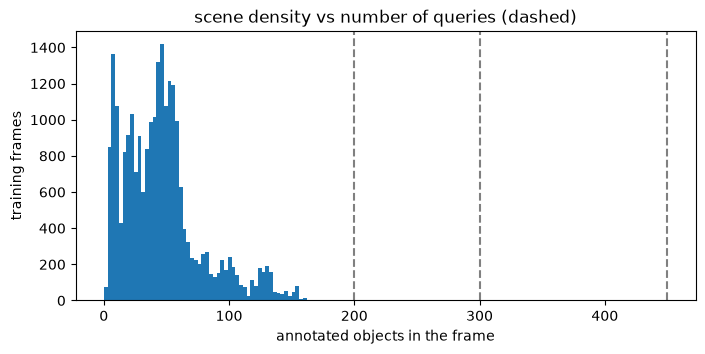

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(objects_per_frame, bins=60)
for queries in (200, 300, 450):
    ax.axvline(queries, color='gray', linestyle='--')
ax.set(xlabel='annotated objects in the frame', ylabel='training frames', title='scene density vs number of queries (dashed)')
plt.show()

## Training recipe (decided on fold 0)

In [8]:
recipe = json.loads((TASK_DIR / 'recipe_decision.json').read_text())
print(json.dumps(recipe, indent=1))

{
 "fold0_mAP": {
  "recipe_notebook": 0.19710725355652856,
  "recipe_warmup_ema": 0.20740864156579406
 },
 "margin": 0.005,
 "adopted": "recipe_warmup_ema"
}


In [9]:
def history(config, fold):
    return json.loads((TASK_DIR / 'runs' / config / f'fold{fold}' / 'result.json').read_text())['history']

recipe_curves = pd.DataFrame({config: [epoch['mAP'] for epoch in history(config, 0)] for config in ['recipe_notebook', BASELINE]},
                             index=pd.Index(range(1, 7), name='epoch'))
display(recipe_curves.round(4))

,recipe_notebook,recipe_warmup_ema
epoch,,
1,0.1971,0.2074
2,0.1669,0.1844
3,0.1705,0.1754
4,0.1682,0.1657
5,0.1744,0.1732
6,0.1743,0.1727


## Experiments on all 5 folds

In [10]:
runs = pd.read_csv(TASK_DIR / 'five_fold_results.csv')
five_fold_runs = runs.groupby('config').filter(lambda group: group.fold.nunique() == 5)
summary_columns = METRICS + ['official_mAP', 'official_APs', 'best_epoch', 'train_minutes', 'ms_per_img']
summary = five_fold_runs.groupby('config')[summary_columns].mean()
summary['CV mAP std'] = five_fold_runs.groupby('config').mAP.std()
display(summary.sort_values('mAP').round(4))

,mAP,AP50,AP75,APs,APm,APl,AR,official_mAP,official_APs,best_epoch,train_minutes,ms_per_img,CV mAP std
config,,,,,,,,,,,,,
matching_bbox7_giou3,0.1578,0.3190,0.1352,0.0533,0.1347,0.3293,0.3838,0.1388,0.0515,1.4,26.5140,27.8124,0.0323
queries_200,0.1663,0.3363,0.1437,0.0522,0.1446,0.3501,0.3591,0.1541,0.0589,1.4,26.9910,26.5803,0.0342
recipe_warmup_ema,0.1691,0.3372,0.1476,0.0589,0.1454,0.3478,0.3948,0.1485,0.0549,1.0,28.7503,25.2919,0.0363
queries_450,0.1697,0.3449,0.1447,0.0616,0.1450,0.3564,0.4133,0.1532,0.0576,1.0,26.9154,27.8227,0.0301
lr_backbone_2e-5,0.1724,0.3490,0.1472,0.0570,0.1490,0.3612,0.3876,0.1561,0.0569,2.2,27.1075,27.1202,0.0363
no_denoising,0.2258,0.4284,0.2085,0.0844,0.1997,0.4274,0.4072,0.2147,0.0728,2.2,22.3030,28.3409,0.0325
no_denoising_640x1152,0.2602,0.4842,0.2461,0.1100,0.2471,0.4589,0.4364,0.2360,0.1138,2.4,29.7228,28.0999,0.0302


In [11]:
map_per_fold = five_fold_runs.pivot_table(index='fold', columns='config', values='mAP')
official_per_fold = five_fold_runs.pivot_table(index='fold', columns='config', values='official_mAP')
display(map_per_fold.round(4))

config,lr_backbone_2e-5,matching_bbox7_giou3,no_denoising,no_denoising_640x1152,queries_200,queries_450,recipe_warmup_ema
fold,,,,,,,
0,0.2138,0.1859,0.2571,0.2751,0.1987,0.1967,0.2074
1,0.1827,0.1806,0.2475,0.2857,0.1832,0.1867,0.1831
2,0.1849,0.1667,0.2372,0.2718,0.1807,0.1831,0.1837
3,0.1650,0.1505,0.2108,0.2594,0.1579,0.1608,0.1601
4,0.1156,0.1056,0.1766,0.2088,0.1109,0.1212,0.1115


In [12]:
def compare(config, reference):
    cv_difference = map_per_fold[config] - map_per_fold[reference]
    official_difference = official_per_fold[config] - official_per_fold[reference]
    return dict(config=config, reference=reference, cv_gain=cv_difference.mean(), cv_folds_better=int((cv_difference > 0).sum()),
                official_gain=official_difference.mean(), official_folds_better=int((official_difference > 0).sum()))

comparisons = [compare(config, BASELINE) for config in map_per_fold.columns if config != BASELINE]
if 'no_denoising_640x1152' in map_per_fold.columns:
    comparisons.append(compare('no_denoising_640x1152', 'no_denoising'))
display(pd.DataFrame(comparisons).round(4))

,config,reference,cv_gain,cv_folds_better,official_gain,official_folds_better
0,lr_backbone_2e-5,recipe_warmup_ema,0.0032,4,0.0076,4
1,matching_bbox7_giou3,recipe_warmup_ema,-0.0113,0,-0.0097,0
2,no_denoising,recipe_warmup_ema,0.0567,5,0.0661,5
3,no_denoising_640x1152,recipe_warmup_ema,0.0910,5,0.0874,5
4,queries_200,recipe_warmup_ema,-0.0029,1,0.0056,3
5,queries_450,recipe_warmup_ema,0.0006,3,0.0046,5
6,no_denoising_640x1152,no_denoising,0.0344,5,0.0213,5


In [13]:
print('best epoch per fold (out of 6)')
display(five_fold_runs.pivot_table(index='fold', columns='config', values='best_epoch'))

best epoch per fold (out of 6)


config,lr_backbone_2e-5,matching_bbox7_giou3,no_denoising,no_denoising_640x1152,queries_200,queries_450,recipe_warmup_ema
fold,,,,,,,
0,1.0,1.0,2.0,2.0,1.0,1.0,1.0
1,2.0,1.0,2.0,4.0,2.0,1.0,1.0
2,6.0,3.0,2.0,2.0,2.0,1.0,1.0
3,1.0,1.0,2.0,1.0,1.0,1.0,1.0
4,1.0,1.0,3.0,3.0,1.0,1.0,1.0


## Comparison of RT-DETR and CNN Training Results

The mean held-out fold mAP after each training epoch is compared for RT-DETR, Faster R-CNN v1 (`lr_scheduler`), Faster R-CNN v2 with scale augmentation, and the RetinaNet baseline. All models were trained for 6 epochs and evaluated using the same protocol.

The first plot shows how mAP changes across epochs, while the second compares mAP against training time. Faster R-CNN v1 appears only in the first plot because its training time per epoch was not recorded.

In [14]:
def epoch_curves(result_files):
    histories = [json.loads(path.read_text())['history'] for path in result_files]
    return np.mean([[epoch['mAP'] for epoch in run] for run in histories], axis=0)

cnn_runs = {
    'Faster R-CNN v1': ROOT / 'faster_rcnn/lr_scheduler',
    'Faster R-CNN v2 + scale aug': ROOT / 'faster_rcnn/faster_rcnn_v2/runs/v2_lr_scheduler_scale_aug',
    'RetinaNet baseline': ROOT / 'retinanet/runs/baseline'}
rtdetr_runs = {f'RT-DETR {config}': TASK_DIR / 'runs' / config
               for config in [BASELINE, 'no_denoising', 'no_denoising_640x1152'] if config in map_per_fold.columns}

In [15]:
curves = {name: epoch_curves([folder / f'fold{fold}/result.json' for fold in range(5)]) for name, folder in {**cnn_runs, **rtdetr_runs}.items()}
curve_table = pd.DataFrame(curves, index=pd.Index(range(1, 7), name='epoch'))
display(curve_table.round(4))

,Faster R-CNN v1,Faster R-CNN v2 + scale aug,RetinaNet baseline,RT-DETR recipe_warmup_ema,RT-DETR no_denoising,RT-DETR no_denoising_640x1152
epoch,,,,,,
1,0.1923,0.2345,0.1613,0.1691,0.2107,0.2501
2,0.1830,0.2332,0.1650,0.1557,0.2251,0.2560
3,0.1972,0.2284,0.1581,0.1473,0.2176,0.2516
4,0.2094,0.2390,0.1616,0.1404,0.2180,0.2551
5,0.2092,0.2385,0.1621,0.1459,0.2185,0.2529
6,0.2090,0.2390,0.1781,0.1444,0.2158,0.2515


In [16]:
def minutes_per_epoch(folder):
    seconds = []
    for fold in range(5):
        run = json.loads((folder / f'fold{fold}/result.json').read_text())['history']
        seconds.append([epoch.get('epoch_seconds', np.nan) for epoch in run])
    return np.nanmean(seconds) / 60

epoch_minutes = {name: minutes_per_epoch(folder) for name, folder in {**cnn_runs, **rtdetr_runs}.items()
                 if name != 'Faster R-CNN v1'}
print('training minutes per epoch:', {name: round(float(value), 1) for name, value in epoch_minutes.items()})

training minutes per epoch: {'Faster R-CNN v2 + scale aug': 10.2, 'RetinaNet baseline': 6.0, 'RT-DETR recipe_warmup_ema': 4.8, 'RT-DETR no_denoising': 3.7, 'RT-DETR no_denoising_640x1152': 5.0}


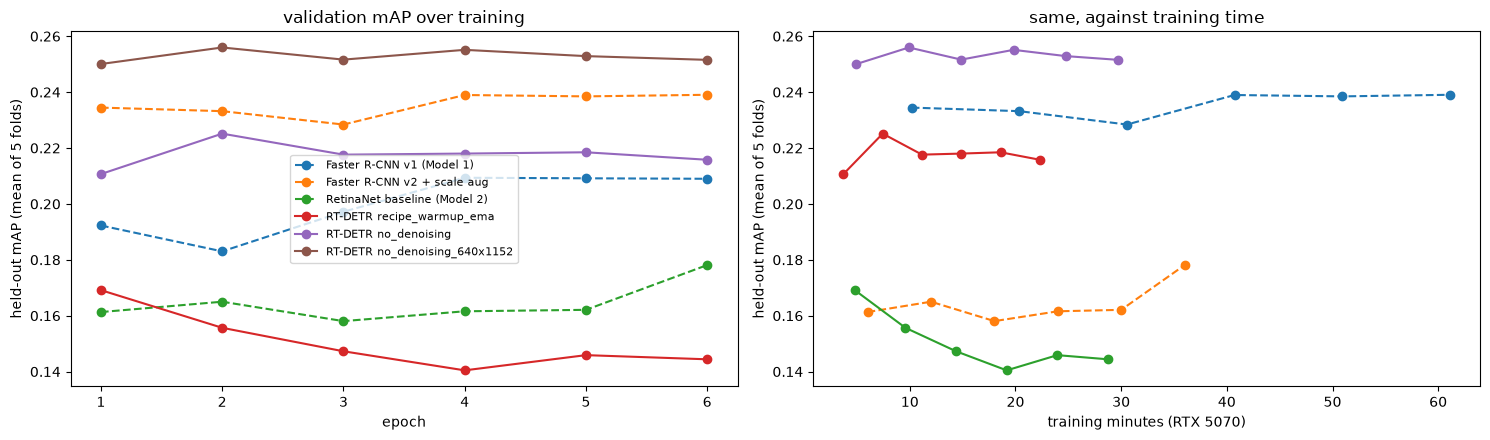

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, values in curves.items():
    style = '-' if name.startswith('RT-DETR') else '--'
    axes[0].plot(range(1, 7), values, style, marker='o', label=name)
    if name in epoch_minutes:
        axes[1].plot(np.arange(1, 7) * epoch_minutes[name], values, style, marker='o', label=name)
axes[0].set(xlabel='epoch', ylabel='held-out mAP (mean of 5 folds)', title='validation mAP over training')
axes[1].set(xlabel='training minutes (RTX 5070)', ylabel='held-out mAP (mean of 5 folds)', title='same, against training time')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(TASK_DIR / 'convergence_vs_cnn.png', dpi=110)
plt.show()

## Small objects and dense scenes


In [18]:
ANALYSIS_DIR = TASK_DIR / 'analysis'
density = pd.read_csv(ANALYSIS_DIR / 'density_and_size.csv')
frames_per_group = density.drop_duplicates('group').set_index('group').frames
print(frames_per_group.to_dict())

{'all frames': 2846, '0-19 objects': 977, '20-39 objects': 656, '40-59 objects': 731, '60-89 objects': 233, '90-999 objects': 249}


In [19]:
all_frames = density[density.group == 'all frames']
print('all frames, mean of 5 checkpoints')
display(all_frames.groupby(['max_dets', 'model'])[METRICS].mean().round(4))

all frames, mean of 5 checkpoints


mAP    AP50    AP75     APs     APm     APl      AR
max_dets model                                                                                  
100      Faster R-CNN v2 + scale aug      0.2219  0.4466  0.1950  0.0958  0.2043  0.4054  0.4093
         RT-DETR (no_denoising_640x1152)  0.2360  0.4569  0.2123  0.1138  0.2198  0.4012  0.4139
         RetinaNet (baseline)             0.1483  0.2944  0.1327  0.0632  0.1358  0.2989  0.2804
500      Faster R-CNN v2 + scale aug      0.2219  0.4466  0.1950  0.0958  0.2043  0.4054  0.4093
         RT-DETR (no_denoising_640x1152)  0.2364  0.4577  0.2127  0.1140  0.2204  0.4017  0.4167
         RetinaNet (baseline)             0.1483  0.2945  0.1327  0.0632  0.1358  0.2988  0.2806

In [20]:
group_order = list(frames_per_group.index)
for max_dets in (100, 500):
    table = density[density.max_dets == max_dets].groupby(['group', 'model']).mAP.mean().unstack().reindex(group_order)
    print(f'mAP by scene density (maxDets {max_dets})')
    display(table.round(4))

mAP by scene density (maxDets 100)


model,Faster R-CNN v2 + scale aug,RT-DETR (no_denoising_640x1152),RetinaNet (baseline)
group,,,
all frames,0.2219,0.2360,0.1483
0-19 objects,0.1203,0.1106,0.0629
20-39 objects,0.2735,0.2948,0.1916
40-59 objects,0.2272,0.2632,0.1797
60-89 objects,0.2691,0.2561,0.1899
90-999 objects,0.2784,0.2756,0.1852


mAP by scene density (maxDets 500)


model,Faster R-CNN v2 + scale aug,RT-DETR (no_denoising_640x1152),RetinaNet (baseline)
group,,,
all frames,0.2219,0.2364,0.1483
0-19 objects,0.1203,0.1106,0.0629
20-39 objects,0.2735,0.2950,0.1916
40-59 objects,0.2272,0.2639,0.1797
60-89 objects,0.2691,0.2570,0.1899
90-999 objects,0.2784,0.2761,0.1852


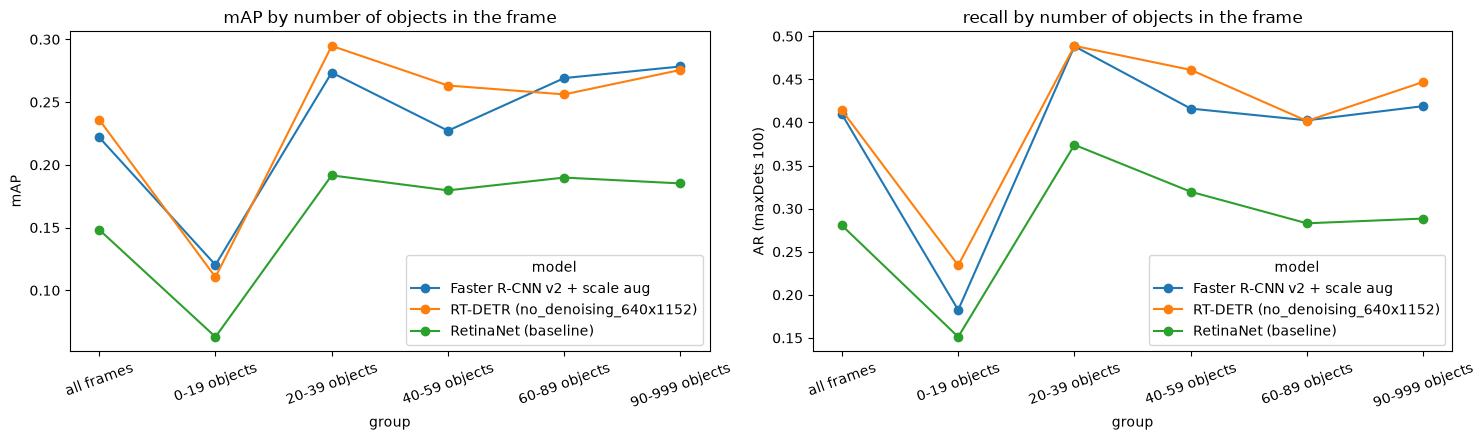

In [21]:
recall = density[density.max_dets == 100].groupby(['group', 'model']).AR.mean().unstack().reindex(group_order)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
density[density.max_dets == 100].groupby(['group', 'model']).mAP.mean().unstack().reindex(group_order).plot(marker='o', ax=axes[0])
recall.plot(marker='o', ax=axes[1])
axes[0].set(ylabel='mAP', title='mAP by number of objects in the frame')
axes[1].set(ylabel='AR (maxDets 100)', title='recall by number of objects in the frame')
for ax in axes:
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.savefig(TASK_DIR / 'density_vs_cnn.png', dpi=110)
plt.show()

## Bipartite matching and NMS


In [22]:
nms_check = pd.read_csv(ANALYSIS_DIR / 'nms_check.csv')
display(nms_check.groupby('variant')[['mAP', 'AP50', 'AP75', 'AR', 'duplicates_per_frame']].mean().round(4))

,mAP,AP50,AP75,AR,duplicates_per_frame
variant,,,,,
+ class-wise NMS 0.5,0.2353,0.4582,0.2109,0.4028,0.0000
+ class-wise NMS 0.7,0.2363,0.4591,0.2118,0.4089,4.4254
as predicted (no NMS),0.2360,0.4569,0.2123,0.4139,8.5824


In [23]:
duplicates = pd.read_csv(ANALYSIS_DIR / 'duplicates.csv')
print('near-duplicate pairs per frame (score >= 0.3, same class, IoU >= 0.5), mean of 5 checkpoints')
display(duplicates.groupby('model').duplicates_per_frame.mean().round(3).to_frame())

near-duplicate pairs per frame (score >= 0.3, same class, IoU >= 0.5), mean of 5 checkpoints


,duplicates_per_frame
model,
Faster R-CNN v2 + scale aug,0.000
RT-DETR (no_denoising_640x1152),8.582
RetinaNet (baseline),0.000
